# 11 — Más cruces del entorno: qué pasa en la ciudad

## Qué contesta este cuaderno

Sigue al 09, **sin datos del hospital**. Amplía el repertorio de patrones de la ciudad antes de
volver al triage (decisión del propietario, `docs/CONTEXTO.md`, 2026-09-30). Son seis preguntas
acotadas a propósito, cada una con mecanismo y literatura detrás, porque **explorar de más lleva al
sobreajuste**:

1. ¿Las fuentes de la ciudad cuentan lo mismo? Policía frente a SIVIGILA.
2. ¿Las aglomeraciones siembran contagio? Feria, puentes y Semana Santa → IRA.
3. ¿El frío pesa más con los colegios abiertos? La «suma de factores», dentro de la ciudad.
4. ¿El clima mueve la violencia?
5. Salud mental e intoxicaciones frente al calendario.
6. ¿El ENSO precede a la IRA o a la EDA?

Las expectativas se escribieron antes de mirar, en `patrones/datos/variables.csv` (filas del
2026-09-30) y en `calendarios/docs/LITERATURA_ENTORNO.md`.

## De dónde salen los datos

Los mismos archivos del cuaderno 09: SIVIGILA (INS), Policía/MinDefensa (datos.gov.co), clima
unificado, ENSO (NOAA), calendario oficial, recesos escolares por resolución, eventos y fiestas
con fuente. Todo agregado por semana o por día.


In [1]:
import sys, pathlib, warnings, os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
import statsmodels.api as sm
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
SES = 170010010301
dias = pd.date_range("2015-01-01", "2026-09-20")
idx = pd.date_range("2015-01-04", "2026-09-13", freq="W-SUN")
def a_semana(s, como="sum"):
    r = getattr(s.resample("W-SAT"), como)(); r.index = r.index - pd.Timedelta(days=6); return r
def anomalia(s):
    s = s.dropna(); s = s - s.groupby(s.index.year).transform("mean")
    return s - s.groupby(s.index.isocalendar().week.values).transform("mean")
def marcar(ini, fin, indice=dias):
    s = pd.Series(0.0, index=indice)
    for a, b in zip(pd.to_datetime(ini), pd.to_datetime(fin)):
        if pd.notna(a): s.loc[a: (b if pd.notna(b) else a)] = 1
    return s

cl = pd.read_csv(RAIZ / "calendarios/clima_unificado.csv.gz", parse_dates=["fecha"]).set_index("fecha")
oni = pd.read_csv(RAIZ / "calendarios/enso_oni.csv", parse_dates=["fecha"])
inst = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila_instituciones.csv.gz", parse_dates=["fecha_inicio_semana"])
ira = np.log(inst[inst.cod_upgd.ne(SES)].groupby("fecha_inicio_semana")["consultas_ira"].sum().replace(0, np.nan))
vig = pd.concat([pd.read_csv(p) for p in sorted((RAIZ / "calendarios").glob("vigilancia_sivigila*.csv.gz"))
                 if "instituciones" not in p.name], ignore_index=True)
vig["fecha_inicio_semana"] = pd.to_datetime(vig["fecha_inicio_semana"])
man = vig[vig.ambito.eq("manizales")].pivot_table(index="fecha_inicio_semana", columns=["evento", "variable"], values="valor", aggfunc="sum")
ev = lambda cod, var="casos_ocurrencia": man[(cod, var)] if (cod, var) in man.columns else None
seg = pd.read_csv(RAIZ / "calendarios/seguridad_mindefensa.csv.gz", parse_dates=["fecha"]).set_index("fecha").reindex(dias)
calc = pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha").reindex(dias)
esc = pd.read_csv(RAIZ / "calendarios/calendario_escolar_manizales.csv", parse_dates=["fecha_inicio", "fecha_fin"])
eventos = pd.read_csv(RAIZ / "calendarios/eventos_manizales_2020_2026.csv")
fiestas = pd.read_csv(RAIZ / "calendarios/fiestas_caldas_2020_2026.csv")
receso = marcar(esc.fecha_inicio, esc.fecha_fin)
ok_ev = eventos.estado.isin(["realizado", "hibrido"])
feria = marcar(*[eventos[ok_ev & eventos.nombre_evento.eq("Feria de Manizales")][c] for c in ("fecha_inicio", "fecha_fin")])
semana_santa = calc.es_semana_santa.fillna(0)
puente = calc.es_puente.fillna(0)
COVID = ("2020-03-01", "2021-12-31")
print("listo:", len(idx), "semanas; IRA ciudad", ira.index.min().date(), "a", ira.index.max().date())


listo: 611 semanas; IRA ciudad 2012-01-01 a 2025-12-28


---
# 1. ¿Las fuentes de la ciudad cuentan lo mismo?

Dos instituciones registran cosas parecidas por caminos distintos: la **Policía** (denuncias) y el **SIVIGILA** (notificación de salud). Si cuentan lo mismo, se validan entre sí. Si no, cada una mide otra cosa. Se compara semanal, en nivel y en anomalía (sin estacionalidad ni nivel del año), 2015-2019 y 2022-2025, fuera de COVID.

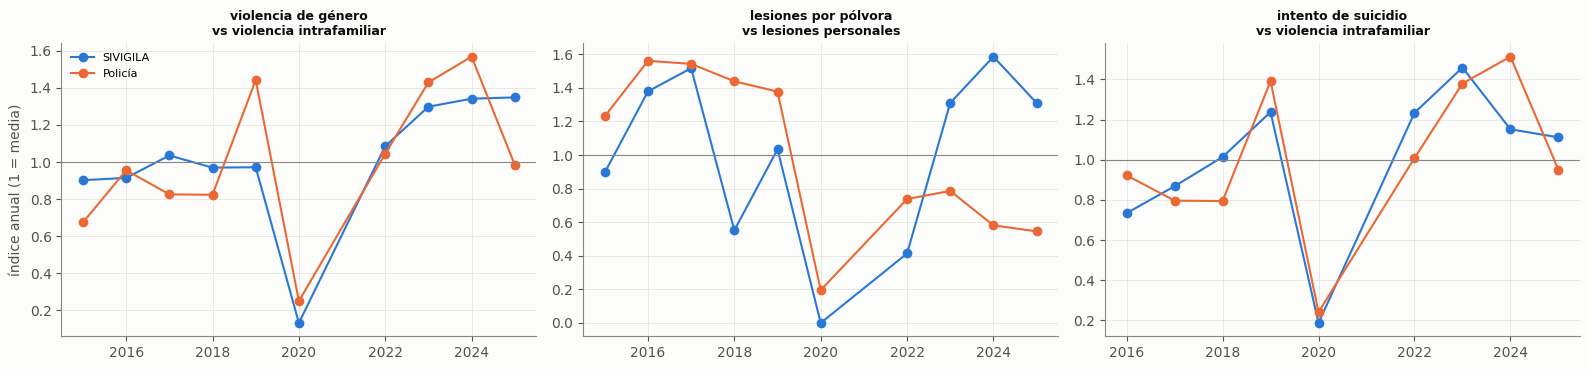

,SIVIGILA,Policía,r semanal (nivel),r semanal (anomalía),r anual,semanas
0,violencia de género (SIVIGILA 875),violencia intrafamiliar (Policía),0.30,0.23,0.79,478
1,lesiones por pólvora (SIVIGILA 452),lesiones personales (Policía),0.09,0.04,0.34,478
2,intento de suicidio (SIVIGILA 356),violencia intrafamiliar (Policía),0.20,0.03,0.86,426


In [2]:
pares = [("violencia de género (SIVIGILA 875)", ev(875), "violencia intrafamiliar (Policía)", a_semana(seg.violencia_intrafamiliar)),
         ("lesiones por pólvora (SIVIGILA 452)", ev(452), "lesiones personales (Policía)", a_semana(seg.lesiones_personales)),
         ("intento de suicidio (SIVIGILA 356)", ev(356), "violencia intrafamiliar (Policía)", a_semana(seg.violencia_intrafamiliar))]
filas = []
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (na, a, nb, b) in zip(axes, pares):
    d = pd.concat([a.rename("a"), b.rename("b")], axis=1).dropna()
    d = d[~d.index.to_series().between(*COVID)]
    anual = d.groupby(d.index.year).sum()
    filas.append({"SIVIGILA": na, "Policía": nb, "r semanal (nivel)": round(d.a.corr(d.b), 2),
                  "r semanal (anomalía)": round(anomalia(d.a).corr(anomalia(d.b)), 2),
                  "r anual": round(anual.a.corr(anual.b), 2), "semanas": len(d)})
    ax.plot(anual.index, anual.a / anual.a.mean(), marker="o", color=AZUL, label="SIVIGILA")
    ax.plot(anual.index, anual.b / anual.b.mean(), marker="o", color=NARANJA, label="Policía")
    ax.set_title(f"{na.split(' (')[0]}\nvs {nb.split(' (')[0]}", fontsize=9); ax.axhline(1, color=MUDO, lw=.8)
axes[0].set_ylabel("índice anual (1 = media)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame(filas)


## Lectura

**Las fuentes de la ciudad se parecen en la tendencia, pero no en la semana.**

| SIVIGILA | Policía | r semanal | r en anomalía | r anual |
|---|---|---|---|---|
| Violencia de género (875) | Violencia intrafamiliar | 0,30 | 0,23 | **0,79** |
| Lesiones por pólvora (452) | Lesiones personales | 0,09 | 0,04 | 0,34 |
| Intento de suicidio (356) | Violencia intrafamiliar | 0,20 | 0,03 | **0,86** |

- **La violencia de género del sector salud y la violencia intrafamiliar de la Policía** van juntas
  año a año (0,79) y algo semana a semana (0,23). Miden fenómenos cercanos por caminos distintos:
  una se notifica en la consulta, la otra se denuncia.
- **Trampa:** el intento de suicidio y la violencia intrafamiliar tienen r = 0,86 anual y 0,03
  semanal. **Esa correlación anual no es un vínculo**: las dos series comparten la tendencia de
  notificación de la década. Semana a semana no se tocan.
- **La pólvora es demasiado rara** (1-2 casos por semana en temporada) para seguir a las lesiones.

**Consecuencia para el modelo.** Donde dos fuentes miden lo mismo, basta con una. Las series anuales
parecidas no prueban nada: hay que mirar la semana.

---
# 2. ¿Las aglomeraciones siembran contagio?

Preregistrado (`aglomeracion_a_ira`). Semanas con Feria, con puente festivo o con Semana Santa, y la IRA de la ciudad (sin el SES, en anomalía) desde 2 semanas antes hasta 4 semanas después. Si juntarse contagia, la IRA debería subir 1-3 semanas **después**. La literatura espera un efecto pequeño.

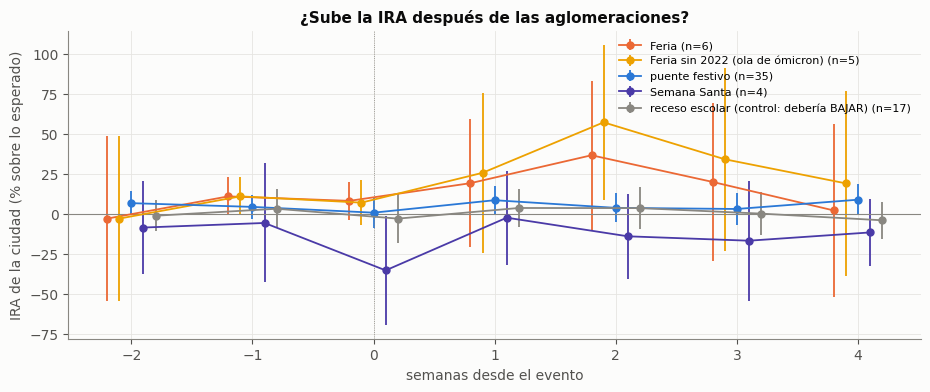

,episodios,sem -2,sem -1,sem +0,sem +1,sem +2,sem +3,sem +4
evento,,,,,,,,
Feria,6,-2.9,11.0,8.2,19.3,36.7,20.0,2.2
Feria sin 2022 (ola de ómicron),5,-2.9,11.0,7.1,25.7,57.3,34.2,19.1
puente festivo,35,6.8,4.5,0.8,8.6,3.9,3.1,8.9
Semana Santa,4,-8.4,-5.6,-35.2,-2.3,-13.9,-16.7,-11.5
receso escolar (control: debería BAJAR),17,-1.1,3.3,-2.9,3.8,3.7,0.2,-3.9


In [3]:
A = anomalia(ira)
A = A[~A.index.to_series().between(*COVID)]
def eventos_semana(senal):
    s = a_semana(senal).reindex(A.index).fillna(0) > 0
    ini = s & ~s.shift(1, fill_value=False)             # primera semana de cada episodio
    return list(s[ini].index)
feria_eps = eventos_semana(feria)
grupos = {"Feria": feria_eps, "Feria sin 2022 (ola de ómicron)": [f for f in feria_eps if f.year != 2022], "puente festivo": eventos_semana(puente), "Semana Santa": eventos_semana(semana_santa),
          "receso escolar (control: debería BAJAR)": eventos_semana(receso)}
K = range(-2, 5)
fig, ax = plt.subplots(figsize=(11, 4)); filas = []
for i, (nom, fechas) in enumerate(grupos.items()):
    M = pd.DataFrame({f: [A.get(f + pd.Timedelta(weeks=k), np.nan) for k in K] for f in fechas}, index=list(K))
    m = M.mean(axis=1); e = 1.96 * M.std(axis=1) / np.sqrt(M.notna().sum(axis=1))
    ax.errorbar(np.array(list(K)) + (i - 2) * .1, 100 * (np.exp(m) - 1), yerr=100 * e, fmt="o-", ms=5, lw=1.3,
                color=[NARANJA, AMARILLO, AZUL, VIOLETA, MUDO][i], label=f"{nom} (n={M.shape[1]})")
    filas.append({"evento": nom, "episodios": M.shape[1], **{f"sem {k:+d}": round(100 * (np.exp(m[k]) - 1), 1) for k in K}})
ax.axhline(0, color=MUDO, lw=.8); ax.axvline(0, color=MUDO, lw=.6, ls=":")
ax.set_xlabel("semanas desde el evento"); ax.set_ylabel("IRA de la ciudad (% sobre lo esperado)")
ax.set_title("¿Sube la IRA después de las aglomeraciones?"); ax.legend(fontsize=8); plt.show()
pd.DataFrame(filas).set_index("evento")


## Lectura

**Juntarse no siembra contagio de forma visible, salvo en enero, y ahí no se sabe qué es.** IRA de la
ciudad, % sobre lo esperado para esa semana del año:

| Evento | episodios | +1 semana | +2 semanas | +3 semanas |
|---|---|---|---|---|
| **Feria** | 6 | +19 % | **+37 %** | +20 % |
| Feria sin 2022 (ómicron) | 5 | +26 % | **+57 %** | +34 % |
| Puente festivo | 35 | +9 % | +4 % | +3 % |
| Semana Santa | 4 | −2 % | −14 % | −17 % |
| Receso escolar | 17 | +4 % | +4 % | 0 % |

- **Después de la Feria, la IRA de la ciudad sube mucho, y sin 2022 sube más.** No es la ola de
  ómicron. **Pero no se puede atribuir a la Feria.**
  - Cae siempre en las mismas semanas de enero, así que no hay un enero «sin Feria» con que
    comparar.
  - El año de referencia incluye 2015-2019, y el calendario de eventos solo marca Ferias desde
    2020.

  Lo que sí muestra es que **en los años recientes enero trae una ola respiratoria** (el cuaderno 10
  la ve también en el hospital: respiratorio en enero, 1,26 de la media), justo después de la
  temporada decembrina, la Feria y el regreso de vacaciones. **Qué parte es de cada una no se puede
  separar con estos datos.**
- **Los puentes festivos no mueven la IRA:** +3 a +9 % con 35 episodios, sin forma de contagio.
- **Semana Santa baja la IRA registrada** (−35 % esa misma semana, −14 a −17 % después).
  Probablemente es menos consulta (la ciudad se vacía y los servicios cierran), no menos contagio.
- **Resultado que no encaja con el 09:** el receso escolar aquí no baja la IRA. En el cuaderno 09 sí
  (−0,20 la misma semana). Aquí se mira el **inicio** de cada receso; allí, las **semanas** de receso.
  Queda como duda: el efecto de cerrar colegios no es robusto al método.

---
# 3. ¿El frío pesa más con los colegios abiertos?

Preregistrado (`frio_por_colegio`). Es la suma de factores del propietario, dentro de la ciudad. Regresión semanal de la anomalía de IRA sobre la anomalía media de temperatura de las 1-5 semanas previas, **separando las semanas de colegio abierto de las de receso**, con errores robustos a la autocorrelación (HAC). Ventana 2022-2025, que es donde hay clima y recesos oficiales.

In [4]:
T = anomalia(a_semana(cl.temp_media_consenso, "mean").loc["2020":])
H = anomalia(a_semana(cl.humedad_consenso, "mean").loc["2020":])
d = pd.DataFrame({"ira": anomalia(ira.loc["2022":"2025"]),
                  "frio_1a5": -pd.concat([T.shift(k) for k in range(1, 6)], axis=1).mean(axis=1),
                  "humedo_1a5": pd.concat([H.shift(k) for k in range(1, 6)], axis=1).mean(axis=1),
                  "abierto": (a_semana(receso).reindex(idx).fillna(0) < 3).astype(float)}).dropna()
res = []
for var in ["frio_1a5", "humedo_1a5"]:
    xs = (d[var] - d[var].mean()) / d[var].std()          # 1 unidad = 1 desviacion tipica
    X = pd.DataFrame({"c": 1.0, "x": xs, "abierto": d.abierto, "x_por_abierto": xs * d.abierto})
    m = sm.OLS(d.ira, X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    b, V = m.params, m.cov_params()
    for nom, w in [("receso", np.array([0, 1, 0, 0])), ("colegio abierto", np.array([0, 1, 0, 1]))]:
        est, se = w @ b.values, np.sqrt(w @ V.values @ w)
        res.append({"factor (1 sd, semanas 1-5 previas)": {"frio_1a5": "frío", "humedo_1a5": "humedad"}[var], "cuando": nom,
                    "efecto sobre IRA %": round(100 * (np.exp(est) - 1), 1), "IC95": f"[{100*(np.exp(est-1.96*se)-1):+.1f}; {100*(np.exp(est+1.96*se)-1):+.1f}]"})
    res.append({"factor (1 sd, semanas 1-5 previas)": {"frio_1a5": "frío", "humedo_1a5": "humedad"}[var], "cuando": "diferencia (interacción)",
                "efecto sobre IRA %": round(100 * b["x_por_abierto"], 1), "IC95": f"p = {m.pvalues['x_por_abierto']:.2f}"})
print(f"{len(d)} semanas; con colegio abierto: {int(d.abierto.sum())}; sd de frio_1a5 = {d.frio_1a5.std():.2f} (se usa 1 sd)")
R = pd.DataFrame(res)
R


209 semanas; con colegio abierto: 160; sd de frio_1a5 = 0.33 (se usa 1 sd)


,"factor (1 sd, semanas 1-5 previas)",cuando,efecto sobre IRA %,IC95
0,frío,receso,9.9,[+2.1; +18.2]
1,frío,colegio abierto,7.6,[+2.7; +12.6]
2,frío,diferencia (interacción),-2.1,p = 0.57
3,humedad,receso,9.7,[+3.1; +16.6]
4,humedad,colegio abierto,6.8,[+2.3; +11.5]
5,humedad,diferencia (interacción),-2.7,p = 0.45


## Lectura

**El frío y la humedad empujan la IRA de la ciudad, estén o no los colegios abiertos.** Efecto de 1
desviación típica de frío o de humedad, medio de las 5 semanas previas, 2022-2025, errores
robustos a la autocorrelación:

| | Receso | Colegio abierto | Diferencia |
|---|---|---|---|
| **Frío** | **+9,9 %** [+2,1; +18,2] | **+7,6 %** [+2,7; +12,6] | −2,1 % (p = 0,57) |
| **Humedad** | **+9,7 %** [+3,1; +16,6] | **+6,8 %** [+2,3; +11,5] | −2,7 % (p = 0,45) |

- **Aquí está la cadena clima → contagio con tamaño.** Una racha de un mes más fría o más húmeda
  de lo normal va seguida de **~8-10 % más IRA** en la ciudad. Coincide con la literatura (2-10 %
  sobre las consultas, `LITERATURA_ENTORNO.md`).
- **La suma de factores colegio × frío no aparece.** El frío pesa lo mismo con y sin colegios. Tal
  vez el contagio que importa en Manizales no es solo el escolar, o 49 semanas de receso son pocas
  para ver la diferencia.
- **Corrección hecha en este cuaderno:** la primera versión daba +33 % porque medía «por grado» y no
  «por desviación típica». Una desviación de la temperatura media de un mes es solo 0,33 °C.

**Límite.** Cambios de apenas 0,3 °C mueven un 8-10 % la IRA, lo que dice que la temperatura puede
ser **un marcador** de otra cosa (humedad, nubosidad, masas de aire) más que la causa directa.

---
# 4. ¿El clima mueve la violencia?

Preregistrado como exploratorio (`clima_a_violencia`). Diario, 2020-2026 sin cuarentenas. Poisson de lesiones personales y violencia intrafamiliar (Policía) contra la lluvia del día y la anomalía de temperatura, **con** el control de calendario del cuaderno 09: día de la semana, festivo, quincena, noches festivas y año.

In [5]:
D = pd.DataFrame(index=dias)
D["lluvia_sd"] = ((cl.precip_consenso_mm - cl.precip_consenso_mm.mean()) / cl.precip_consenso_mm.std()).reindex(dias)
tz = cl.temp_media_consenso; tz = (tz - tz.groupby(tz.index.month).transform("mean")) / tz.std()
D["temp_anom_sd"] = tz.reindex(dias)
D["festivo"] = calc.es_festivo.fillna(0); D["quincena"] = calc.es_quincena.fillna(0)
md_ = pd.Series(list(zip(dias.month, dias.day)), index=dias)
D["noche_festiva"] = md_.isin([(12, 7), (12, 8), (12, 24), (12, 25), (12, 31), (1, 1)]).astype(float)
ok = D.notna().all(axis=1) & ~dias.to_series().between("2020-03-01", "2021-06-30").values & (dias >= "2020-01-01")
X = pd.concat([D[ok], pd.get_dummies(pd.Index(dias[ok].dayofweek), prefix="d", drop_first=True).set_index(dias[ok]).astype(float),
               pd.get_dummies(pd.Index(dias[ok].year), prefix="a", drop_first=True).set_index(dias[ok]).astype(float)], axis=1)
X.insert(0, "c", 1.0)
filas = []
for col, nom in [("lesiones_personales", "lesiones personales"), ("violencia_intrafamiliar", "violencia intrafamiliar"),
                 ("lesiones_transito", "lesiones de tránsito")]:
    m = sm.GLM(seg[col][ok], X, family=sm.families.Poisson()).fit(cov_type="HC0")
    for v, et in [("lluvia_sd", "lluvia (+1 sd)"), ("temp_anom_sd", "más cálido que lo normal (+1 sd)")]:
        b, s = m.params[v], m.bse[v]
        filas.append({"serie": nom, "factor": et, "efecto %": round(100 * (np.exp(b) - 1), 1),
                      "IC95": f"[{100*(np.exp(b-1.96*s)-1):+.1f}; {100*(np.exp(b+1.96*s)-1):+.1f}]"})
print(f"{int(ok.sum())} días")
pd.DataFrame(filas)


1942 días


,serie,factor,efecto %,IC95
0,lesiones personales,lluvia (+1 sd),-5.7,[-10.1; -1.1]
1,lesiones personales,más cálido que lo normal (+1 sd),4.5,[-0.2; +9.4]
2,violencia intrafamiliar,lluvia (+1 sd),-1.2,[-5.9; +3.8]
3,violencia intrafamiliar,más cálido que lo normal (+1 sd),-0.3,[-5.7; +5.3]
4,lesiones de tránsito,lluvia (+1 sd),-1.1,[-4.9; +2.8]
5,lesiones de tránsito,más cálido que lo normal (+1 sd),0.1,[-4.1; +4.5]


## Lectura

**La lluvia vacía la calle: las riñas bajan cuando llueve.**
- **Lesiones personales: −5,7 % por desviación típica de lluvia** [−10,1; −1,1], con el calendario
  ya descontado.
- Días más cálidos que lo normal: +4,5 %, en el borde.
- La **violencia intrafamiliar no responde al clima** (−1,2 % y −0,3 %). Pasa dentro de la casa.
- El **tránsito** registrado tampoco, igual que en el cuaderno 07.

Encaja con la literatura: el calor se asocia a más violencia y la lluvia reduce la exposición en la
calle.

---
# 5. Salud mental e intoxicaciones frente al calendario

Exploratorio (`calendario_salud_mental`). Semanal, 2015-2025 sin COVID. Intento de suicidio (SIVIGILA 356) e intoxicaciones (365) según el mes del año y según los días festivos y de quincena de la semana.

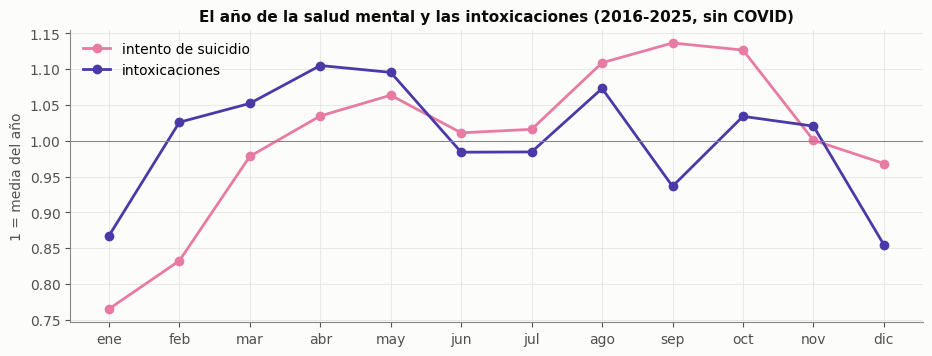

fecha_inicio_semana,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,dic
intento de suicidio,0.77,0.83,0.98,1.03,1.06,1.01,1.02,1.11,1.14,1.13,1.00,0.97
intoxicaciones,0.87,1.03,1.05,1.11,1.10,0.98,0.98,1.07,0.94,1.03,1.02,0.85


,serie,por cada día de,efecto %,IC95
0,intento de suicidio,festivos,7.4,[-2.1; +17.9]
1,intento de suicidio,quincena,4.1,[-4.3; +13.4]
2,intoxicaciones,festivos,-1.1,[-10.6; +9.4]
3,intoxicaciones,quincena,-4.2,[-13.0; +5.5]


In [6]:
W = pd.DataFrame({"intento de suicidio": ev(356), "intoxicaciones": ev(365)})
W = W[~W.index.to_series().between(*COVID)].loc["2016":"2025"]
W["festivos"] = a_semana(calc.es_festivo.fillna(0)).reindex(W.index)
W["quincena"] = a_semana(calc.es_quincena.fillna(0)).reindex(W.index)
meses = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
fig, ax = plt.subplots(figsize=(11, 3.8)); perfil = {}
for c, col in [("intento de suicidio", MAGENTA), ("intoxicaciones", VIOLETA)]:
    s = W[c]; rel = s / s.groupby(s.index.year).transform("mean")
    p = rel.groupby(rel.index.month).mean(); perfil[c] = p.round(2)
    ax.plot(p.index, p.values, marker="o", color=col, lw=2, label=c)
ax.axhline(1, color=MUDO, lw=.8); ax.set_xticks(range(1, 13), meses); ax.set_ylabel("1 = media del año"); ax.legend()
ax.set_title("El año de la salud mental y las intoxicaciones (2016-2025, sin COVID)"); plt.show()
filas = []
for c in ["intento de suicidio", "intoxicaciones"]:
    X = pd.concat([pd.DataFrame({"c": 1.0, "festivos": W.festivos, "quincena": W.quincena}, index=W.index),
                   pd.get_dummies(pd.Index(W.index.year), prefix="a", drop_first=True).set_index(W.index).astype(float)], axis=1)
    m = sm.GLM(W[c], X, family=sm.families.Poisson()).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    for v in ["festivos", "quincena"]:
        b, s = m.params[v], m.bse[v]
        filas.append({"serie": c, "por cada día de": v, "efecto %": round(100 * (np.exp(b) - 1), 1),
                      "IC95": f"[{100*(np.exp(b-1.96*s)-1):+.1f}; {100*(np.exp(b+1.96*s)-1):+.1f}]"})
display(pd.DataFrame(perfil).rename(index=dict(enumerate(meses, 1))).T)
pd.DataFrame(filas)


## Lectura

**La salud mental tiene su propio año, al revés de la fiesta.**

| | ene | feb | ago | sep | oct | dic |
|---|---|---|---|---|---|---|
| Intento de suicidio | **0,77** | 0,83 | 1,11 | **1,14** | **1,13** | 0,97 |
| Intoxicaciones | **0,87** | 1,03 | 1,07 | 0,94 | 1,03 | **0,85** |

- **Los intentos de suicidio bajan en enero-febrero y suben en agosto-octubre**, justo cuando no hay
  fiestas. No es la temporada festiva. Coincide con lo que describe la literatura de muchos países
  (más en la segunda mitad del año, menos en vacaciones).
- **Ni los festivos ni la quincena** mueven de forma clara el intento de suicidio ni las
  intoxicaciones: intervalos que cruzan el cero.
- **Las intoxicaciones notificadas bajan en diciembre y enero**, aunque se bebe más. El alcohol no
  se notifica como intoxicación, así que esto no lo contradice.

---
# 6. ¿El ENSO precede a la IRA o a la EDA?

Exploratorio (`enso_a_salud`). Mensual, 2015-2019 y 2022-2025. El ONI del mes contra la anomalía de IRA y de EDA de la ciudad 0 a 6 meses después. Las anomalías van sin el nivel del año ni la forma estacional.

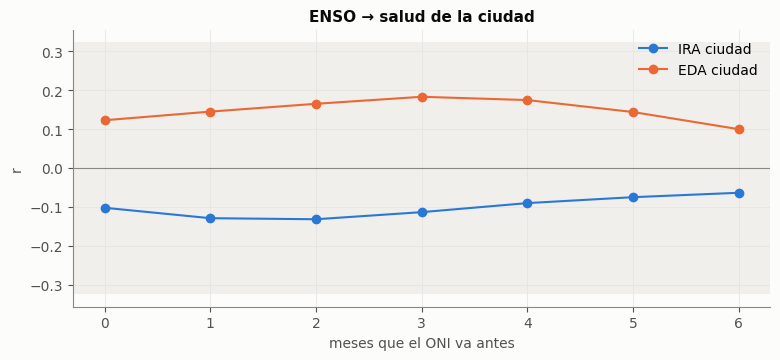

,0 meses,1 meses,2 meses,3 meses,4 meses,5 meses,6 meses,meses
serie,,,,,,,,
IRA ciudad,-0.10,-0.13,-0.13,-0.11,-0.09,-0.07,-0.06,110
EDA ciudad,0.12,0.15,0.17,0.18,0.17,0.14,0.10,110


In [7]:
o = oni.set_index(oni.fecha.dt.to_period("M"))["oni"]
def mensual(s):
    m = s.groupby(s.index.to_period("M")).sum()
    m = m[~((m.index >= pd.Period("2020-03", "M")) & (m.index <= pd.Period("2021-12", "M")))]
    m = np.log(m.replace(0, np.nan)).dropna()
    m = m - m.groupby(m.index.year).transform("mean")
    return m - m.groupby(m.index.month).transform("mean")
series = {"IRA ciudad": mensual(np.exp(ira).loc["2015":"2025"]), "EDA ciudad": mensual(ev(998, "casos_eda_total").loc["2015":"2025"])}
fig, ax = plt.subplots(figsize=(9, 3.6)); filas = []
for i, (nom, s) in enumerate(series.items()):
    rs = [s.corr(o.shift(k).reindex(s.index)) for k in range(0, 7)]
    ax.plot(range(7), rs, marker="o", color=[AZUL, NARANJA][i], label=nom)
    filas.append({"serie": nom, **{f"{k} meses": round(r, 2) for k, r in enumerate(rs)}, "meses": len(s)})
n = min(len(s) for s in series.values()); um = 1.96 / np.sqrt(n / 3)       # aproximado: autocorrelacion alta del ONI
ax.axhspan(-um, um, color="#f0efec", lw=0); ax.axhline(0, color=MUDO, lw=.8)
ax.set_xlabel("meses que el ONI va antes"); ax.set_ylabel("r"); ax.set_title("ENSO → salud de la ciudad"); ax.legend(); plt.show()
pd.DataFrame(filas).set_index("serie")


## Lectura

**El ENSO apenas se asoma en la salud de la ciudad.** Correlación mensual del ONI con la anomalía,
2015-2025 sin COVID (110 meses):
- **IRA: −0,10 a −0,13.** El Niño, más cálido, va con un poco menos de IRA. Es la dirección
  esperada.
- **EDA: +0,15 a +0,18 a 2-4 meses.** El Niño va con algo más de diarrea unos meses después.
- **Ninguna pasa el umbral aproximado (~0,32)**, que es alto porque el ONI cambia muy despacio.

El ENSO **es contexto de fondo**, no un gatillo. Actúa a través de la temperatura (cuaderno 09:
ENSO → temperatura +0,49), y lo que empuja la IRA es la temperatura del mes.

---
# 7. Resumen: lo que la ciudad hace consigo misma

| Cruce | Resultado | Fuerza |
|---|---|---|
| **Frío y humedad → IRA** (1-5 semanas) | **+8-10 % por desviación típica**, con y sin colegios | **Firme** |
| Colegio × frío (suma de factores) | Sin diferencia (p = 0,57) | No aparece |
| **Enero → ola respiratoria** (tras diciembre, Feria y regreso) | +20 a +57 % a 1-3 semanas del inicio de la Feria | **Fuerte, pero no atribuible a la Feria** |
| Puentes → IRA | +3 a +9 %, sin forma | Débil |
| Semana Santa → IRA registrada | −14 a −35 % | Menos consulta, no menos contagio |
| **Lluvia → riñas** | **−5,7 %** | Firme |
| Clima → violencia intrafamiliar | Nada | — |
| **Salud mental** | Baja en enero-febrero, sube en agosto-octubre | Clara |
| ENSO → IRA / EDA | −0,1 / +0,17, sin pasar el umbral | Contexto de fondo |
| Policía ↔ SIVIGILA | Tendencia común; semana a semana, poco | Se validan a medias |

**Para el repertorio del modelo, pocas cosas y firmes:**
1. **Frío y humedad del último mes** → temporada respiratoria. Es la única cadena con tamaño y con
   literatura.
2. **Enero** como ventana respiratoria tras la temporada festiva. Se trata como un periodo, sin
   separar causas que no se pueden separar.
3. **Calendario festivo y lluvia** → la calle: más riñas en fiesta y menos con lluvia.
4. Todo lo demás queda **de contexto**, sin entrar al modelo: ENSO, salud mental, puentes.

Eso responde al principio de parsimonia del 30-09: **no todo lo que se mide entra**.